# Racetrap: transient → DFT → mass-to-charge spectrum

An experimental framework, with no decay fitting or correction. Run all cells from top to bottom with the project's `.venv` kernel. Change the **experiment settings** cell and rerun everything below it.

The reviewed starting notebook is `notebooks/test.ipynb`. This notebook is self-contained so the pipeline can be reviewed and adjusted here before moving stable functions into a module. Existing prototypes are left intact.

1. Load the raw oscilloscope trace, keeping seconds and volts internally.
2. Check sampling, select the acquisition interval, subtract a baseline, and apply a window.
3. Evaluate the DFT with `numpy.fft.rfft` and normalize the one-sided amplitude.
4. Calibrate positive frequencies using $m/z=A/f_0^2$, where $f_0=f_\mathrm{observed}/h$ and $h$ is the detector harmonic.
5. Inspect plots and candidate peaks; optionally export spectra and the settings used.

**Calibration status:** the default uses the handwritten sketch's approximate 120 kHz / nominal 39 reference as an explicitly unconfirmed demonstration. It does not identify the ions in this measurement. Replace it with measured references for the current trap voltages, geometry, ion energy and detector harmonic. A single reference fixes the scale but cannot validate the model or its uncertainty.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/k_20ms_avg128_26.5degC.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or its notebooks folder.")

## Experiment settings

All column indices are zero-based. `time_scale_to_s` and `voltage_scale_to_v` convert source units to SI; this raw CSV already uses s and V. Time bounds refer to the CSV's trigger-relative timestamps and are `[start, stop)`.

The 0.1–10.1 ms interval below is an editable starting choice to exclude the immediate trigger region, not a measured recovery time. Inspect the raw trace before choosing it. `None` bounds use the available record. With `baseline_interval_s=None`, subtract the analysis segment's mean.

For real calibration set `mode="references"`, supply measured `frequency_hz`, known `mz` (mass in u divided by charge number), and harmonic `h` for each reference. No reference is selected automatically from the strongest peak. `spectrum_harmonic` applies to the spectral branch you want to map; a mixture of harmonics requires separate interpretation. Temperature/voltage metadata are recorded, not used as automatic corrections.

In [2]:
EXPERIMENT = {
    "id": "k_20ms_exploration",
    "waveform": "data/k_20ms_avg128_26.5degC.csv",
    "csv": {"header": None, "time_column": 3, "voltage_column": 4,
            "time_scale_to_s": 1.0, "voltage_scale_to_v": 1.0},
    "acquisition": {"temperature_c": 26.5, "averages": 128,
                    "ion_energy_ev": None, "electrode_voltages_v": {},
                    "notes": "Fill in the actual experiment conditions."},
    "processing": {"start_s": 0.0001, "stop_s": 0.0101,
                   "baseline_interval_s": [-0.0009, -0.0001],
                   "window": "blackmanharris",  # or hann / rectangular
                   "zero_padding_factor": 1,
                   "max_grid_error_samples": 0.02},
    "calibration": {
        "mode": "demo",  # demo / references
        "id": "UNCONFIRMED-sketch-example",
        "spectrum_harmonic": 1,
        "references": [
            # {"label": "confirmed ion", "frequency_hz": ..., "mz": ..., "h": 1},
        ],
    },
    "peaks": {"frequency_range_hz": [20_000.0, 500_000.0],
              "min_amplitude_v": 0.0001, "min_separation_hz": 500.0,
              "max_rows": 20},
    "plots": {"frequency_range_khz": [0, 500], "mz_range": [1, 150]},
    "export": {"enabled": False, "directory": "outputs/k_20ms_exploration"},
}

## Reusable processing steps

The loader accepts raw traces only. The `clean_FFT` and `clean_SPEC` files already contain processed spectra and must not be Fourier transformed again. Nonfinite, reversed or materially nonuniform timestamps are rejected; small export rounding is tolerated against the full sampling grid.

The DFT uses the selected segment's length $N$. Its amplitude is $2|X_k|/\sum w$, with DC and an even-length Nyquist bin undoubled. This estimates a bin-centered steady sinusoid's peak amplitude in volts; it is not a power spectrum, abundance, charge or pressure. Windowing broadens peaks. Zero padding interpolates the grid; the acquisition duration and window still limit resolution.

In [3]:
def sampling_interval(time_s, max_grid_error_samples=0.02):
    t = np.asarray(time_s, dtype=float)
    if t.ndim != 1 or t.size < 4 or not np.isfinite(t).all():
        raise ValueError("Need at least four finite time samples.")
    if np.any(np.diff(t) <= 0):
        raise ValueError("Timestamps must be strictly increasing.")
    if not np.isfinite(max_grid_error_samples) or not 0 <= max_grid_error_samples < 0.5:
        raise ValueError("Grid tolerance must be finite and in [0, 0.5) samples.")
    dt = (t[-1] - t[0]) / (t.size - 1)
    error = float(np.max(np.abs(t - (t[0] + np.arange(t.size) * dt))) / dt)
    if error > max_grid_error_samples:
        raise ValueError(f"Nonuniform time grid: maximum error {error:.4g} samples.")
    return dt, error


def load_waveform(path, csv_options, tolerance):
    raw = pd.read_csv(path, header=csv_options["header"])
    tc, vc = csv_options["time_column"], csv_options["voltage_column"]
    if tc == vc or min(tc, vc) < 0 or max(tc, vc) >= raw.shape[1]:
        raise ValueError("Choose distinct time/voltage columns; processed spectra are not raw traces.")
    scales = [csv_options["time_scale_to_s"], csv_options["voltage_scale_to_v"]]
    if not np.isfinite(scales).all() or min(scales) <= 0:
        raise ValueError("Unit conversion factors must be finite and positive.")
    t = pd.to_numeric(raw.iloc[:, tc], errors="raise").to_numpy(float) * scales[0]
    v = pd.to_numeric(raw.iloc[:, vc], errors="raise").to_numpy(float) * scales[1]
    if not np.isfinite(v).all():
        raise ValueError("Voltage must contain only finite values.")
    dt, error = sampling_interval(t, tolerance)
    return pd.DataFrame({"time_s": t, "voltage_v": v}), dt, error


def interval_mask(t, bounds):
    lo = t[0] if bounds[0] is None else float(bounds[0])
    hi = np.nextafter(t[-1], np.inf) if bounds[1] is None else float(bounds[1])
    if not np.isfinite([lo, hi]).all() or lo >= hi:
        raise ValueError("Time intervals require finite start < stop.")
    # Reject requests extending beyond the record, allowing half a sample at edges.
    margin = (t[-1] - t[0]) / (len(t) - 1) / 2
    if lo < t[0] - margin or hi > t[-1] + margin:
        raise ValueError("Requested interval extends beyond the waveform.")
    return (t >= lo) & (t < hi)


def compute_spectrum(trace, settings):
    t, v = trace.time_s.to_numpy(), trace.voltage_v.to_numpy()
    if t.shape != v.shape or not np.isfinite(v).all():
        raise ValueError("Provide matching finite time and voltage samples.")
    dt, error = sampling_interval(t, settings["max_grid_error_samples"])
    selected = interval_mask(t, [settings["start_s"], settings["stop_s"]])
    if selected.sum() < 4:
        raise ValueError("Analysis interval must contain at least four samples.")
    baseline_mask = (selected if settings["baseline_interval_s"] is None
                     else interval_mask(t, settings["baseline_interval_s"]))
    if not baseline_mask.any():
        raise ValueError("Baseline interval contains no samples.")
    baseline = float(v[baseline_mask].mean())
    segment = pd.DataFrame({"time_s": t[selected], "voltage_v": v[selected] - baseline})
    n = len(segment)
    phase = 2 * np.pi * np.arange(n) / n
    windows = {
        "rectangular": lambda: np.ones(n),
        "hann": lambda: 0.5 - 0.5 * np.cos(phase),
        "blackmanharris": lambda: (0.35875 - 0.48829 * np.cos(phase)
                                   + 0.14128 * np.cos(2 * phase)
                                   - 0.01168 * np.cos(3 * phase)),
    }
    if settings["window"] not in windows:
        raise ValueError(f"Choose a window from {list(windows)}.")
    padding = settings["zero_padding_factor"]
    if isinstance(padding, bool) or not isinstance(padding, (int, np.integer)) or padding < 1:
        raise ValueError("zero_padding_factor must be a positive integer.")
    weights = windows[settings["window"]]()
    nfft = n * padding
    transform = np.fft.rfft(segment.voltage_v.to_numpy() * weights, n=nfft)
    amplitude = 2 * np.abs(transform) / weights.sum()
    amplitude[0] /= 2
    if nfft % 2 == 0:
        amplitude[-1] /= 2
    spectrum = pd.DataFrame({"frequency_hz": np.fft.rfftfreq(nfft, dt),
                             "amplitude_v": amplitude})
    stats = {"sample_count": n, "sample_rate_hz": 1 / dt,
             "nyquist_hz": 0.5 / dt, "duration_s": n * dt,
             "unpadded_bin_spacing_hz": 1 / (n * dt),
             "fft_grid_spacing_hz": 1 / (nfft * dt), "baseline_v": baseline,
             "max_grid_error_samples": error,
             "actual_start_s": float(segment.time_s.iloc[0]),
             "actual_last_sample_s": float(segment.time_s.iloc[-1])}
    return segment, spectrum, stats

## Calibration model and candidate peaks

For fixed trap settings, the supplied presentation and sketch motivate $f_0\propto\sqrt{z/m}$. We therefore fit the one-parameter model $m/z=A/f_0^2$ by unweighted least squares in m/z, with zero intercept. `A` has units (u/e)·Hz². The optional harmonic numbers make the observed-frequency convention explicit. The model is a starting assumption, not an instrument-specific validated calibration law. See also the primary study [The Electrostatic Ion Beam Trap](https://arxiv.org/abs/1105.0499) on square-root charge/mass scaling.

Review the residuals with several confirmed ions before adding an offset or a more flexible model. Residuals at calibration points are diagnostics, not an independent validation. Bins outside the reference frequency span are flagged; a single reference provides no validated span. Conversion relabels each bin, retaining voltage amplitude without interpolation or a density/Jacobian transformation.

Peaks are thresholded local maxima with greedy minimum separation, reported at FFT-bin centers. Thresholds are exploratory and should be set using matched background measurements. Harmonics, switching pickup and interference can also produce peaks; the table does not assign species.

In [4]:
def fit_calibration(settings):
    if not settings["id"]:
        raise ValueError("Provide a calibration ID.")
    if settings["mode"] == "demo":
        refs = [{"label": "sketch: nominal K, UNCONFIRMED", "frequency_hz": 120_000.,
                 "mz": 39., "h": 1}]
        status = "DEMONSTRATION ONLY — unconfirmed 120 kHz / nominal 39 reference"
    elif settings["mode"] == "references":
        refs = settings["references"]
        status = "User-supplied references; review assignments and residuals"
    else:
        raise ValueError("Calibration mode must be demo or references.")
    if not refs:
        raise ValueError("Supply confirmed calibration references before using references mode.")
    table = pd.DataFrame(refs)
    required = {"label", "frequency_hz", "mz", "h"}
    if not required.issubset(table.columns):
        raise ValueError(f"Each reference needs {sorted(required)}.")
    values = table[["frequency_hz", "mz", "h"]].to_numpy(float)
    h = settings["spectrum_harmonic"]
    if (not np.isfinite(values).all() or np.any(values <= 0)
            or np.any(values[:, 2] != np.floor(values[:, 2]))
            or not np.isfinite(h) or h < 1 or int(h) != h):
        raise ValueError("Positive finite references and integer harmonics >= 1 are required.")
    f0 = values[:, 0] / values[:, 2]
    x = 1 / f0**2
    coefficient = float(np.dot(x, values[:, 1]) / np.dot(x, x))
    table["fundamental_hz"] = f0
    table["fitted_mz"] = coefficient * x
    table["residual_mz"] = table.fitted_mz - table.mz
    table["residual_ppm"] = 1e6 * table.residual_mz / table.mz
    model = {"id": settings["id"], "mode": settings["mode"], "status": status,
             "coefficient_mz_hz2": coefficient, "spectrum_harmonic": int(h),
             "reference_fundamental_range_hz": [float(f0.min()), float(f0.max())],
             "has_reference_span": bool(f0.max() > f0.min())}
    return model, table


def map_to_mz(spectrum, model):
    result = spectrum.loc[spectrum.frequency_hz > 0].copy()  # exclude singular DC bin
    f0 = result.frequency_hz / model["spectrum_harmonic"]
    result["mz_u_per_e"] = model["coefficient_mz_hz2"] / f0**2
    lo, hi = model["reference_fundamental_range_hz"]
    result["within_reference_span"] = model["has_reference_span"] & f0.between(lo, hi)
    return result.sort_values("mz_u_per_e").reset_index(drop=True)


def candidate_peaks(spectrum, settings, nyquist_hz):
    lo, hi = settings["frequency_range_hz"]
    threshold, separation = settings["min_amplitude_v"], settings["min_separation_hz"]
    if (not np.isfinite([lo, hi, threshold, separation]).all()
            or not 0 <= lo < hi <= nyquist_hz or min(threshold, separation) < 0):
        raise ValueError("Peak band must lie inside Nyquist; thresholds must be nonnegative.")
    f, a = spectrum.frequency_hz.to_numpy(), spectrum.amplitude_v.to_numpy()
    ix = np.flatnonzero((a[1:-1] > a[:-2]) & (a[1:-1] >= a[2:])) + 1
    ix = ix[(f[ix] >= lo) & (f[ix] <= hi) & (a[ix] >= threshold)]
    selected = []
    for i in ix[np.argsort(-a[ix])]:
        if all(abs(f[i] - f[j]) >= separation for j in selected):
            selected.append(int(i))
    return spectrum.iloc[selected].copy().reset_index(drop=True)

## Run the pipeline

`run_pipeline` is the orchestration boundary for later batch processing. The source file hash and a snapshot of the settings travel with the result. The FFT is calculated once and reused for plotting, peak picking and calibration.

In [5]:
def run_pipeline(experiment):
    settings = deepcopy(experiment)
    path = (ROOT / settings["waveform"]).resolve()
    trace, dt, error = load_waveform(path, settings["csv"],
                                    settings["processing"]["max_grid_error_samples"])
    segment, spectrum, stats = compute_spectrum(trace, settings["processing"])
    calibration, residuals = fit_calibration(settings["calibration"])
    reference_observed = residuals.frequency_hz.to_numpy(float)
    if np.any(reference_observed > stats["nyquist_hz"]):
        raise ValueError("A calibration reference exceeds this acquisition's Nyquist frequency.")
    peaks = candidate_peaks(spectrum, settings["peaks"], stats["nyquist_hz"])
    mass_peaks = map_to_mz(peaks, calibration).sort_values("amplitude_v", ascending=False)
    metadata = {"experiment": settings, "source_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                "statistics": stats, "calibration": calibration,
                "versions": {"numpy": np.__version__, "pandas": pd.__version__}}
    return {"trace": trace, "segment": segment, "spectrum": spectrum,
            "mass_spectrum": map_to_mz(spectrum, calibration), "peaks": mass_peaks,
            "calibration_residuals": residuals, "metadata": metadata}

result = run_pipeline(EXPERIMENT)
print(result["metadata"]["calibration"]["status"])
display(pd.Series(result["metadata"]["statistics"], name="Acquisition / DFT"))
display(result["calibration_residuals"])
display(result["peaks"].head(EXPERIMENT["peaks"]["max_rows"]))

DEMONSTRATION ONLY — unconfirmed 120 kHz / nominal 39 reference


sample_count               5.000000e+04
sample_rate_hz             5.000000e+06
nyquist_hz                 2.500000e+06
duration_s                 1.000000e-02
unpadded_bin_spacing_hz    1.000000e+02
fft_grid_spacing_hz        1.000000e+02
baseline_v                -8.370642e-03
max_grid_error_samples     8.607957e-03
actual_start_s             1.001999e-04
actual_last_sample_s       1.010000e-02
Name: Acquisition / DFT, dtype: float64

,label,frequency_hz,mz,h,fundamental_hz,fitted_mz,residual_mz,residual_ppm
0,"sketch: nominal K, UNCONFIRMED",120000.0,39.0,1,120000.0,39.0,0.0,0.0


,frequency_hz,amplitude_v,mz_u_per_e,within_reference_span
551,91000.001829,0.137074,67.817894,False
301,272900.005484,0.011747,7.540845,False
554,88700.001783,0.011445,71.380542,False
270,295700.005942,0.003510,6.422801,False
310,266200.005350,0.002403,7.925214,False
605,49300.000991,0.002196,231.064509,False
268,297400.005977,0.002071,6.349582,False
541,99100.001992,0.001486,57.184690,False
430,181900.003655,0.001227,16.973120,False
542,98500.001979,0.001045,57.883478,False


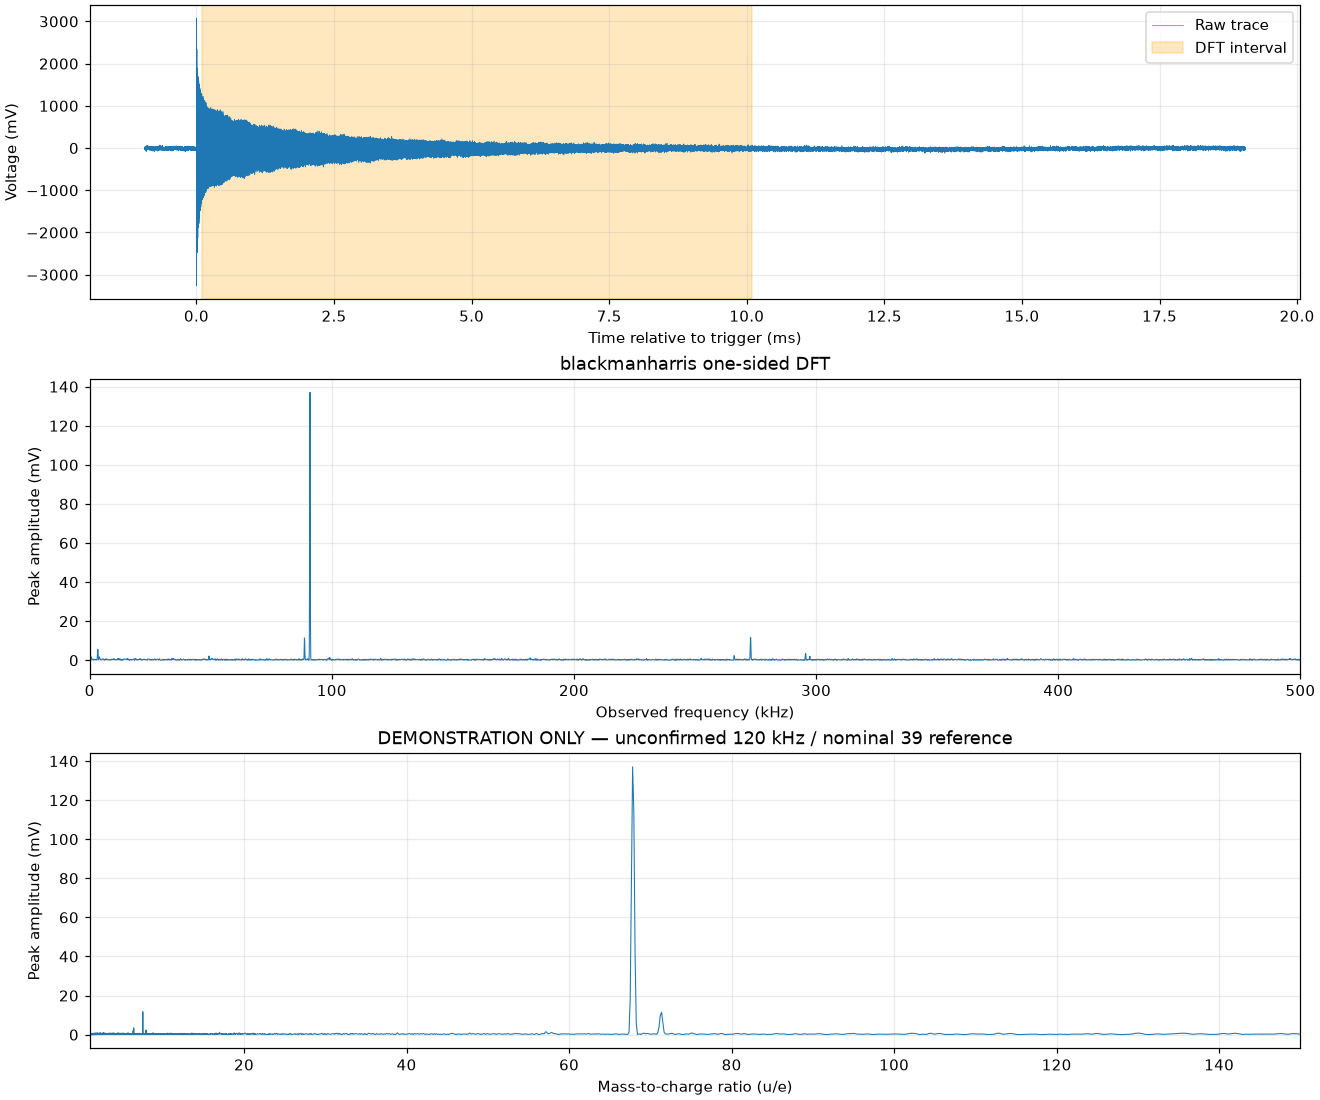

In [6]:
trace, segment = result["trace"], result["segment"]
spectrum, mass = result["spectrum"], result["mass_spectrum"]
fig, axes = plt.subplots(3, 1, figsize=(12, 10), layout="constrained")
axes[0].plot(trace.time_s * 1e3, trace.voltage_v * 1e3, lw=0.4, label="Raw trace")
axes[0].axvspan(segment.time_s.iloc[0] * 1e3, segment.time_s.iloc[-1] * 1e3,
               color="orange", alpha=0.25, label="DFT interval")
axes[0].set(xlabel="Time relative to trigger (ms)", ylabel="Voltage (mV)")
axes[0].legend()
axes[1].plot(spectrum.frequency_hz / 1e3, spectrum.amplitude_v * 1e3, lw=0.7)
axes[1].set(xlabel="Observed frequency (kHz)", ylabel="Peak amplitude (mV)",
            xlim=EXPERIMENT["plots"]["frequency_range_khz"],
            title=f"{EXPERIMENT['processing']['window']} one-sided DFT")
axes[2].plot(mass.mz_u_per_e, mass.amplitude_v * 1e3, lw=0.7)
axes[2].set(xlabel="Mass-to-charge ratio (u/e)", ylabel="Peak amplitude (mV)",
            xlim=EXPERIMENT["plots"]["mz_range"],
            title=result["metadata"]["calibration"]["status"])
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## Inspect the supplied processed references separately

These files are from a **4 ms** experiment; the raw trace above is labelled **20 ms**. Their preprocessing, calibration and amplitude normalization have not been supplied. They are useful context, not a numerical ground truth for this run. `Mass_u` is the source's label and does not establish charge state. No calibration coefficient is inferred from the tallest reference peak.

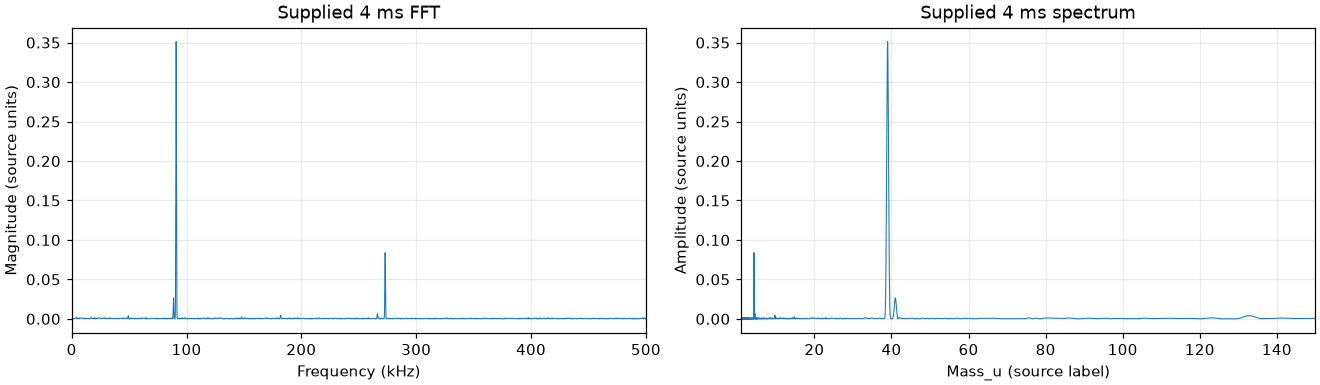

In [7]:
reference_fft = pd.read_csv(ROOT / "data/k_4ms_avg128_26.5degC_clean_FFT.csv")
reference_mass = pd.read_csv(ROOT / "data/k_4ms_avg128_26.5degC_clean_SPEC.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
axes[0].plot(reference_fft.frequency_kHz, reference_fft.magnitude, lw=0.7)
axes[0].set(xlabel="Frequency (kHz)", ylabel="Magnitude (source units)",
            xlim=EXPERIMENT["plots"]["frequency_range_khz"], title="Supplied 4 ms FFT")
axes[1].plot(reference_mass.Mass_u, reference_mass.Amplitude, lw=0.7)
axes[1].set(xlabel="Mass_u (source label)", ylabel="Amplitude (source units)",
            xlim=EXPERIMENT["plots"]["mz_range"], title="Supplied 4 ms spectrum")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

## Numerical sanity checks

Synthetic steady tones verify physical frequency units and amplitude normalization for even/odd FFT lengths, all windows and zero padding. Separate checks cover baseline removal and Nyquist scaling, the inverse-square model with harmonics, and rejection of invalid sampling and missing references. These checks validate the numerical framework; they do not establish the real experiment's calibration.

In [8]:
for n in (1000, 1001):
    fs, amplitude, tone_bin = 1_000_000., 0.02, 100
    t = np.arange(n) / fs
    tone = pd.DataFrame({"time_s": t, "voltage_v": amplitude * np.cos(2*np.pi*tone_bin*np.arange(n)/n)})
    for window in ("rectangular", "hann", "blackmanharris"):
        for padding in (1, 2):
            options = dict(EXPERIMENT["processing"], start_s=None, stop_s=None,
                           baseline_interval_s=None, window=window, zero_padding_factor=padding)
            _, s, stats = compute_spectrum(tone, options)
            peak = s.loc[s.amplitude_v.idxmax()]
            assert np.isclose(peak.frequency_hz, tone_bin*fs/n)
            assert np.isclose(peak.amplitude_v, amplitude, rtol=1e-8)

options = dict(options, window="rectangular", zero_padding_factor=1)
t = np.arange(1000) / fs
nyquist = pd.DataFrame({"time_s": t, "voltage_v": amplitude * (-1.)**np.arange(1000)})
_, s, _ = compute_spectrum(nyquist, options)
assert np.isclose(s.amplitude_v.iloc[-1], amplitude)  # Nyquist must not be doubled
# A constant baseline is removed from the actual processing path.
constant = pd.DataFrame({"time_s": t, "voltage_v": np.full(1000, 0.125)})
_, dc_spectrum, _ = compute_spectrum(constant, options)
assert np.allclose(dc_spectrum.amplitude_v, 0.)

known_A = 39 * 100_000.**2
model_options = {"mode": "references", "id": "synthetic", "spectrum_harmonic": 2,
                 "references": [{"label": str(mz), "frequency_hz": 2*np.sqrt(known_A/mz),
                                 "mz": mz, "h": 2} for mz in (20., 39., 80.)]}
model, residuals = fit_calibration(model_options)
assert np.isclose(model["coefficient_mz_hz2"], known_A)
assert np.max(np.abs(residuals.residual_mz)) < 1e-10
mapped = map_to_mz(pd.DataFrame({"frequency_hz": [0., 200_000.], "amplitude_v": [0., 1.]}), model)
assert len(mapped) == 1 and np.isclose(mapped.mz_u_per_e.iloc[0], 39.)

for invalid in (np.array([0., 1., 1., 3.]), np.array([0., 1., 2.3, 3.]),
                np.array([0., 1., np.nan, 3.])):
    try:
        sampling_interval(invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid timestamps accepted")
try:
    fit_calibration(dict(model_options, references=[]))
except ValueError:
    pass
else:
    raise AssertionError("Empty references accepted")
print("Numerical sanity checks passed.")

Numerical sanity checks passed.


## Optional export and next experiments

Enable export in the settings cell to write both spectra, the candidate table, calibration residuals and a JSON record of settings, calibration, versions and source hash. Existing files in the selected output directory will be overwritten when this cell runs. Exports are ignored by Git.

Next steps: measure switching recovery to choose the time interval; collect a matched background to set peak thresholds; confirm reference species, charge states and harmonics at the actual electrode voltages; check calibration residuals and independent reference ions; then consider batch processing and improved peak estimation. Decay analysis remains deferred.

### Local sources reviewed

- `docs/st.docx`: image-current detection, orbital trapping and residual-gas / partial-pressure goals.
- `docs/Apresentação Nenad.pptx`, slides 6 and 8–10: frequency-dependent mass analysis and harmonic notation.
- `docs/reunião 24_9_2026.pptx`, slides 9–12: acquisition-limited resolution, Blackman–Harris processing and dedicated acquisition goals.
- `docs/WhatsApp Image 2026-11-06 at 12.45.17.jpeg`: trigger/electrode timing sketch, approximate nominal 39 / 120 kHz example and inverse-square scaling. The timing annotations are not treated as confirmed acquisition settings.

In [9]:
if EXPERIMENT["export"]["enabled"]:
    destination = ROOT / EXPERIMENT["export"]["directory"]
    destination.mkdir(parents=True, exist_ok=True)
    for key in ("spectrum", "mass_spectrum", "peaks", "calibration_residuals"):
        result[key].to_csv(destination / f"{key}.csv", index=False)
    (destination / "metadata.json").write_text(
        json.dumps(result["metadata"], indent=2, allow_nan=False) + "\n")
    print(f"Exported results to {destination}")
else:
    print("Export disabled. Results are available in the result dictionary.")

Export disabled. Results are available in the result dictionary.
